# 1.Load the modules

In [40]:
import pandas as pd
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder

In [3]:
df = pd.read_csv('https://raw.githubusercontent.com/gscdit/Breast-Cancer-Detection/refs/heads/master/data.csv')
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [4]:
df.columns

Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32'],
      dtype='object')

In [5]:
df.drop(columns = ['id','Unnamed: 32'],inplace=True)

In [6]:
df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [7]:
df.shape

(569, 31)

# 2.Train test split


In [142]:
x_train,x_test,y_train,y_test = train_test_split(df.iloc[:,1:], df.iloc[:,0], test_size=0.2)

In [143]:
x_train

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
426,10.480,14.98,67.49,333.6,0.09816,0.10130,0.063350,0.022180,0.1925,0.06915,...,12.130,21.57,81.41,440.4,0.1327,0.29960,0.29390,0.09310,0.3020,0.09646
8,13.000,21.82,87.50,519.8,0.12730,0.19320,0.185900,0.093530,0.2350,0.07389,...,15.490,30.73,106.20,739.3,0.1703,0.54010,0.53900,0.20600,0.4378,0.10720
309,13.050,13.84,82.71,530.6,0.08352,0.03735,0.004559,0.008829,0.1453,0.05518,...,14.730,17.40,93.96,672.4,0.1016,0.05847,0.01824,0.03532,0.2107,0.06580
116,8.950,15.76,58.74,245.2,0.09462,0.12430,0.092630,0.023080,0.1305,0.07163,...,9.414,17.07,63.34,270.0,0.1179,0.18790,0.15440,0.03846,0.1652,0.07722
264,17.190,22.07,111.60,928.3,0.09726,0.08995,0.090610,0.065270,0.1867,0.05580,...,21.580,29.33,140.50,1436.0,0.1558,0.25670,0.38890,0.19840,0.3216,0.07570
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
484,15.730,11.28,102.80,747.2,0.10430,0.12990,0.119100,0.062110,0.1784,0.06259,...,17.010,14.20,112.50,854.3,0.1541,0.29790,0.40040,0.14520,0.2557,0.08181
366,20.200,26.83,133.70,1234.0,0.09905,0.16690,0.164100,0.126500,0.1875,0.06020,...,24.190,33.81,160.00,1671.0,0.1278,0.34160,0.37030,0.21520,0.3271,0.07632
254,19.450,19.33,126.50,1169.0,0.10350,0.11880,0.137900,0.085910,0.1776,0.05647,...,25.700,24.57,163.10,1972.0,0.1497,0.31610,0.43170,0.19990,0.3379,0.08950
12,19.170,24.80,132.40,1123.0,0.09740,0.24580,0.206500,0.111800,0.2397,0.07800,...,20.960,29.94,151.70,1332.0,0.1037,0.39030,0.36390,0.17670,0.3176,0.10230


In [144]:
y_train

,diagnosis
426,B
8,M
309,B
116,B
264,M
...,...
484,B
366,M
254,M
12,M


# 3.Scaling the values

In [145]:
sc = StandardScaler()
x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)


In [146]:
x_train

array([[-1.02739113, -1.01214516, -0.99955835, ..., -0.31383782,
         0.19510436,  0.69333716],
       [-0.30645726,  0.54478574, -0.17016858, ...,  1.40625133,
         2.37465339,  1.2940589 ],
       [-0.29215301, -1.27163364, -0.36870816, ..., -1.19414563,
        -1.27023309, -1.0215724 ],
       ...,
       [ 1.53879016, -0.02199174,  1.44633321, ...,  1.31331471,
         0.77128853,  0.30404262],
       [ 1.4586864 ,  1.22309774,  1.69088092, ...,  0.95985086,
         0.44547966,  1.0199866 ],
       [-1.32606374, -0.25188943, -1.31747037, ..., -0.96256587,
        -0.71330856, -0.151253  ]])

In [147]:
x_test

array([[ 0.01109695, -1.49015026, -0.06530321, ..., -0.83489229,
        -1.28146788, -0.74022879],
       [-1.11321659, -0.43171039, -1.09779192, ..., -0.88288415,
         0.25127831,  0.21846494],
       [-1.11607744, -1.0349073 , -1.12141771, ..., -1.33934004,
         1.05697316, -0.21613542],
       ...,
       [ 1.19548832,  0.12596222,  1.16033674, ...,  1.21123679,
         0.26411807, -0.02148815],
       [-1.25997813, -0.21319378, -1.24825093, ..., -0.73281437,
         0.44226972,  0.06576752],
       [-1.33722105,  0.51291873, -1.32037178, ..., -1.34162537,
        -0.8384962 ,  0.44723142]])

# 4.Leable Encode the output column

In [148]:
lb = LabelEncoder()
y_train = lb.fit_transform(y_train)
y_test = lb.transform(y_test)

In [149]:
y_train

array([0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1,
       0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0,
       1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1,
       0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1,
       1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0,
       1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0,
       1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0,
       0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0,
       1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0,
       0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0,
       1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0,

# 5.convert numpy array to torch tensor

In [150]:
x_train_tensor = torch.from_numpy(x_train)
x_test_tensor = torch.from_numpy(x_test)
y_train_tensor = torch.from_numpy(y_train.astype('int64'))
y_test_tensor = torch.from_numpy(y_test.astype('int64'))

What happened

Your model’s predictions had shape (455, 1), one column of 455 probabilities. Your labels had shape (455,), a flat list of 455 values. When you multiply those two in PyTorch, it doesn’t raise an error. It “broadcasts” them into a 455×455 table so the shapes fit, comparing every prediction against every label instead of matching row 1 with row 1, row 2 with row 2, and so on.

A small example:

python
pred  = torch.tensor([[0.9], [0.1]])   # shape (2, 1)
label = torch.tensor([1., 0.])         # shape (2,)
(pred * label).shape                   # -> (2, 2), not (2,)

You wanted 2 comparisons and got 4.

Why it’s “silent”
No error message appeared.
The loss was still a normal-looking number.
The loss still went down over the epochs.

But the model was being rewarded for matching the average label across the whole dataset, not for getting each tumor right. So it learned “about 37% of tumors are malignant” instead of learning from the 30 features. The code ran, the loss fell, and the model was still wrong.

Why it’s a good lesson

It shows that a training loop can run without errors and still be broken. The habit it teaches is to print and check tensor shapes at each step (print(y_pred.shape, y.shape)), and to be suspicious if accuracy is oddly low.

One caution

That bullet in the post claims the bug happened to you. It did happen in your first notebook, and the current version still has it until you apply the .view(-1, 1) fix. So after you fix it and see accuracy jump, the line is honest, and it’s a strong story: “my accuracy was stuck at ~60%, I found the cause was a shape mismatch, and fixing it brought accuracy to ~97%.”

If you’d rather not mention it, you can swap the bullet for something simpler:

• How gradient descent, sigmoid, and binary cross-entropy work together, built entirely by hand


In [156]:
y_train_tensor = torch.from_numpy(y_train.astype('float64')).view(-1, 1)
y_test_tensor  = torch.from_numpy(y_test.astype('float64')).view(-1, 1)

In [49]:
x_train_tensor

tensor([[-1.0068, -0.9375, -1.0332,  ..., -1.8200, -0.2621, -1.2191],
        [ 0.0787,  1.7687,  0.0134,  ..., -0.9241, -0.9199, -1.0511],
        [-0.3277,  0.5870, -0.1874,  ...,  1.4976,  2.7438,  1.3317],
        ...,
        [ 1.4922,  1.6498,  1.5201,  ...,  1.0548,  1.4715,  1.6172],
        [ 0.9175,  0.6579,  0.9496,  ...,  0.6409,  0.3813, -0.4801],
        [-0.5569, -1.1798, -0.5560,  ..., -0.3480, -0.3216,  0.2702]],
       dtype=torch.float64)

# 6.Defing a neural network


In [116]:
class mySimpleNN:

  def __init__(self, x):

    self.weights = torch.rand(x.shape[1], 1, dtype=torch.float64, requires_grad=True)
    self.bias = torch.zeros(1, dtype=torch.float64, requires_grad=True)

  def forword(self, x):
    z = torch.matmul(x, self.weights) + self.bias
    y_pred = torch.sigmoid(z)
    return y_pred

  def loss_function(self, y_pred, y):
    # Clamp predictions to avoid log(0)
    epsilon = 1e-7
    y_pred = torch.clamp(y_pred, epsilon, 1 - epsilon)

    # Calculate loss
    loss = -(y * torch.log(y_pred) + (1 - y) * torch.log(1 - y_pred)).mean()
    return loss

# 7.Dedining importeand Parameters

In [107]:
learning_rate = 0.1
epochs = 125

# 8.treaning pipeline

We turn off gradient tracking during the parameter update because updating the weights is a manual optimization step, not a part of your neural network's mathematical forward pass.
If you do not use torch.no_grad(), PyTorch will think the subtraction (model.weights - ...) is a new layer or operation in your neural network.
Here is exactly why that ruins your training loop:

1. It Explodes Memory (The Computational Graph Break)

PyTorch dynamically builds a computational graph to keep track of every mathematical operation so it can calculate gradients later.
• With torch.no_grad(): PyTorch simply changes the values of weights and bias in place and moves on.
• Without torch.no_grad(): PyTorch tracks the update itself. In the next epoch, it tracks the next update on top of that update. By epoch 100, you have a massive chain of 100 tracked updates stored in your RAM/VRAM, quickly causing an Out of Memory (OOM) error.

2. It Corrupts Your Gradient Calculations

If PyTorch tracks your parameter updates, the math behind loss.backward() gets contaminated. Instead of calculating the gradients of your model's layers, PyTorch will try to calculate the derivative of the optimizer's subtraction step itself, leading to wrong gradients or a runtime error.


In [157]:
# create a model
model = mySimpleNN(x_train_tensor)

loss_history = []
print(model.forword(x_train_tensor).shape, y_train_tensor.shape)

# define loop
for i in range(epochs):

  # forword pass
  y_pred = model.forword(x_train_tensor)

  # loss calculation
  loss = model.loss_function(y_pred, y_train_tensor)

  # backword pass
  loss.backward()

  # parameters update
  with torch.no_grad():
    model.weights -= learning_rate * model.weights.grad
    model.bias -= learning_rate * model.bias.grad

  # Zero gradients
  model.weights.grad.zero_()
  model.bias.grad.zero_()

  # print loss in each epoch
  print(f'Epoch: {i + 1}, Loss: {loss.item()}')

  loss_history.append(loss.item())

torch.Size([455, 1]) torch.Size([455, 1])
Epoch: 1, Loss: 0.511346303234253
Epoch: 2, Loss: 0.4964483760743031
Epoch: 3, Loss: 0.4820981948499945
Epoch: 4, Loss: 0.46827493581444796
Epoch: 5, Loss: 0.4549594159433224
Epoch: 6, Loss: 0.4421342205020342
Epoch: 7, Loss: 0.42978377124799777
Epoch: 8, Loss: 0.41789430114543674
Epoch: 9, Loss: 0.4064537011348544
Epoch: 10, Loss: 0.39545120961500235
Epoch: 11, Loss: 0.38487693216838453
Epoch: 12, Loss: 0.37431104900136564
Epoch: 13, Loss: 0.36242078252362825
Epoch: 14, Loss: 0.35100108205046354
Epoch: 15, Loss: 0.34003846829112755
Epoch: 16, Loss: 0.32951642553042887
Epoch: 17, Loss: 0.31941579174485063
Epoch: 18, Loss: 0.30971569061783666
Epoch: 19, Loss: 0.3003947240535963
Epoch: 20, Loss: 0.2914321203042543
Epoch: 21, Loss: 0.2828086218262889
Epoch: 22, Loss: 0.27450702478066147
Epoch: 23, Loss: 0.26651238474185973
Epoch: 24, Loss: 0.2588119578522421
Epoch: 25, Loss: 0.25139496114159693
Epoch: 26, Loss: 0.24425222827254459
Epoch: 27, Loss:

In [158]:
model.weights

tensor([[ 0.4550],
        [ 0.3361],
        [ 0.6192],
        [ 1.1731],
        [ 0.5436],
        [ 0.2795],
        [ 0.4569],
        [ 0.0705],
        [-0.3155],
        [ 0.1574],
        [ 0.2519],
        [ 0.3180],
        [ 0.4363],
        [ 0.5212],
        [-0.0781],
        [ 0.2327],
        [-0.1692],
        [-0.0246],
        [ 0.4073],
        [-0.5126],
        [ 0.8945],
        [ 0.8992],
        [ 0.4000],
        [ 0.8059],
        [ 0.4986],
        [-0.1037],
        [ 0.2179],
        [ 0.5756],
        [ 0.7023],
        [ 0.2419]], dtype=torch.float64, requires_grad=True)

In [159]:
model.bias

tensor([-0.1655], dtype=torch.float64, requires_grad=True)

In [160]:
with torch.no_grad():
  y_pred = model.forword(x_test_tensor)

# 9.Calculating aaccrucy

In [163]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score

# 1. Convert true labels to a flat NumPy array
y_true = y_test_tensor.detach().cpu().numpy().flatten()

# 2. Flatten your model predictions and convert to a NumPy array
y_pred_probs = y_pred.detach().cpu().numpy().flatten()

# 3. Apply the 0.5 threshold to convert probabilities to binary 0 or 1
y_pred_binary = (y_pred_probs >= 0.5).astype(int)

# 4. Calculate your metrics (y_true goes FIRST)
accuracy = accuracy_score(y_true, y_pred_binary)
precion = precision_score(y_true, y_pred_binary)
recall = recall_score(y_true, y_pred_binary)
f1 = f1_score(y_true, y_pred_binary)

print(f"Accuracy Score: {accuracy:.4f}")
print(f"precision_score: {precion:.4f}")
print(f"recall_score: {recall:.4f}")
print(f"f1_score: {f1:}")

Accuracy Score: 0.9912
precision_score: 0.9767
recall_score: 1.0000
f1_score: 0.9882352941176471


# 10.Loss curve

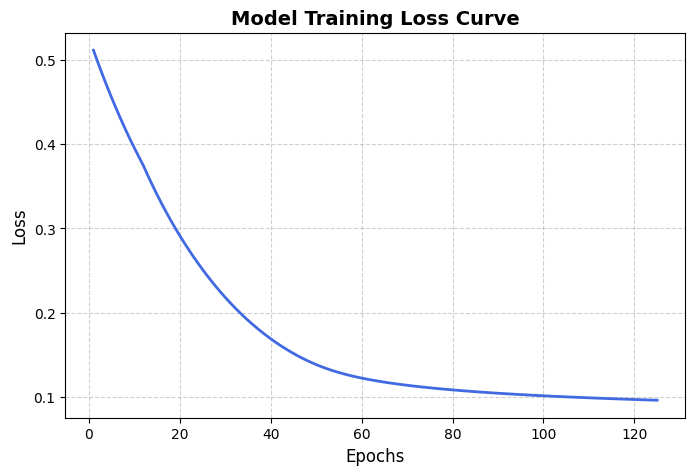

In [164]:
import matplotlib.pyplot as plt
# Plotting the loss history
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), loss_history, color='royalblue', linewidth=2)
plt.title('Model Training Loss Curve', fontsize=14, fontweight='bold')
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

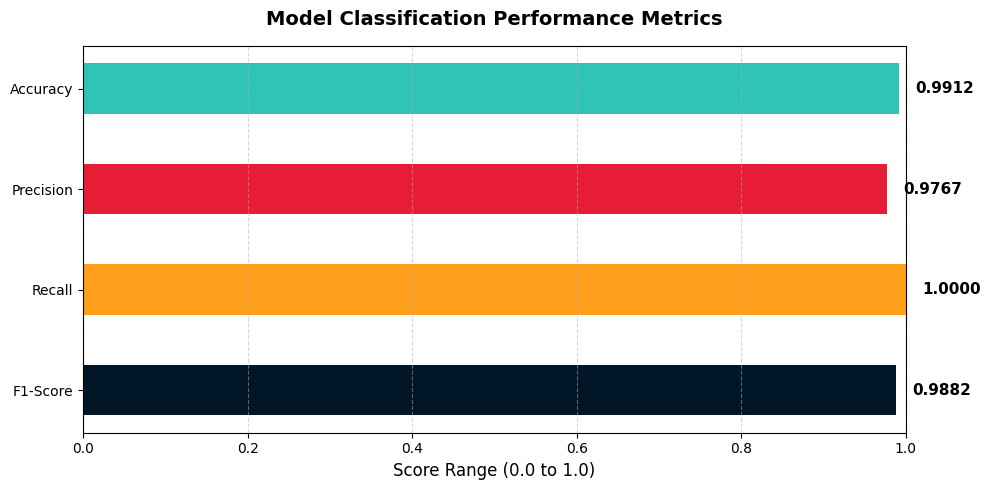

In [165]:
import matplotlib.pyplot as plt

# 1. Set up metrics data
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
metrics_values = [accuracy, precion, recall, f1]
colors = ['#2ec4b6', '#e71d36', '#ff9f1c', '#011627'] # High contrast palette

# 2. Build the horizontal bar plot
plt.figure(figsize=(10, 5))
bars = plt.barh(metrics_names, metrics_values, color=colors, height=0.5)

# 3. Style details
plt.title('Model Classification Performance Metrics', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Score Range (0.0 to 1.0)', fontsize=12)
plt.xlim(0.0, 1.0) # Keeps scale bounded between 0 and 1
plt.grid(axis='x', linestyle='--', alpha=0.5)

# 4. Add data value labels on top of each bar
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.02, bar.get_y() + bar.get_height()/2,
             f'{width:.4f}',
             va='center', ha='left', fontsize=11, fontweight='bold')

plt.gca().invert_yaxis() # Puts Accuracy at the top
plt.tight_layout()
plt.show()


In [152]:
  y_pred.shape

torch.Size([455, 1])

In [153]:
y_train_tensor.shape

torch.Size([455])

In [155]:
y_test_tensor

tensor([0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0,
        0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1,
        1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1,
        0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0,
        1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0])